# Case Study 06 — Predicting Loan Amount from Income

**Simple linear regression · slope and intercept · least squares · R² and RMSE · inference on the slope · confidence vs
prediction intervals · residual diagnostics · heteroscedasticity · log-log models and elasticity · extrapolation ·
leverage and influence**

| | |
|---|---|
| **Domain** | Retail lending: personal-loan pre-offers |
| **Stakeholder** | Head of Personal Loans (Product) |
| **Difficulty** | Beginner–Intermediate |
| **Importance** | 🔴 MUST GO THROUGH |
| **Builds on** | Case 01 (CIs), Case 05 (correlation) |
| **Data** | 3,000 recently disbursed personal loans |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. See `src/generate_data.py`.

**What you will learn**

1. What the regression equation **Y = β₀ + β₁X + ε** means, and how to read the **slope** and the **intercept** in
   business terms.
2. How least squares works, and what **R²**, **RMSE**, the **standard error** and the **p-value** of the slope tell you.
3. The difference between a **confidence interval** (for the *average* customer) and a **prediction interval** (for
   *one* customer). This is the most common practical mistake with regression.
4. How to read **residual plots**, detect **heteroscedasticity**, and fix it with a **log-log model**, which gives an
   **elasticity**.
5. Why **extrapolation** and **high-leverage points** are dangerous.

## Section 1 — Business context

You are a data scientist supporting the **Personal Loans** product team. Branch staff currently guess how much to
offer walk-in customers, so offers vary a lot between branches. The Head of Personal Loans writes:

> *"I want a simple rule for branch staff: enter the customer's verified monthly income, get a suggested loan
> amount to pre-offer, plus a realistic range. Also, for our planning deck: how much more do customers borrow
> for every extra ₹10,000 of monthly income?"*

You have **3,000 personal loans disbursed in the last six months**, with the customer's verified monthly income and the
loan amount they took.

## Section 2 — Business questions

1. How strongly is loan amount related to income?
2. On average, how much more do customers borrow per extra ₹10,000 of monthly income?
3. For a customer with a given income, what amount should we suggest, and what range is realistic?
4. Is a simple straight-line rule good enough, and where does it break?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | How strong? | How much of the variation in loan amount is explained by income? | R², correlation |
| 2 | ₹ per ₹10k income | Slope β₁ of loan amount on income, with uncertainty | OLS slope, SE, 95% CI, t-test |
| 3 | Suggested amount + range | Predicted **mean** for that income (CI), and the range for **one** new customer (PI) | Confidence interval vs **prediction interval** |
| 4 | Is a straight line OK? | Are the regression assumptions reasonable? | Residual plots, Breusch-Pagan test, Q-Q plot, leverage/Cook's distance; log-log model; holdout validation |

> **Regression is not the same as correlation.** A correlation is symmetric and unitless. Regression has a direction
> (predict Y from X) and units (₹ of loan per ₹ of income), and it produces predictions with intervals.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
import statsmodels.stats.api as sms
from statsmodels.stats.outliers_influence import OLSInfluence

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_money, fmt_p, rng_for_case
from plotting import set_style, save_fig, add_note, thousands_formatter, COLORS, PRIMARY, HIGHLIGHT, INK, INK_MUTED

CASE_DIR = ROOT / "case_studies" / "06_loan_amount_simple_regression"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
rng = rng_for_case(606)
kfmt = thousands_formatter("₹", "k", 1e3, 0)
lfmt = thousands_formatter("₹", "L", 1e5, 1)
PRODUCT_CAP = 2_000_000

## Section 4 — Load the data

In [2]:
raw = pd.read_csv(PATHS["data"] / "loans_income_amount.csv")
print(f"{raw.shape[0]:,} loans × {raw.shape[1]} columns")
raw.head()

3,000 loans × 5 columns


,loan_id,disbursal_month,employment_type,monthly_income,loan_amount
0,PL6100000,2025-06,Salaried,"81,300.0000",270000
1,PL6100001,2025-01,Self-employed,"23,500.0000",70000
2,PL6100002,2025-06,Self-employed,"78,300.0000",260000
3,PL6100003,2025-05,Salaried,"30,200.0000",70000
4,PL6100004,2025-06,Salaried,"42,600.0000",80000


| Column | Meaning | Role |
|---|---|---|
| `monthly_income` | Verified monthly income (₹) | **Predictor X** |
| `loan_amount` | Disbursed amount (₹), product range ₹50k–₹20 lakh | **Outcome Y** |
| `employment_type`, `disbursal_month` | Context | Not used in this case (Case 07 adds more predictors) |

## Section 5 — Data quality

In [3]:
print(f"Duplicates: {raw['loan_id'].duplicated().sum()},  missing: {raw.isna().sum().sum()}")
print(f"Loan amount range: {fmt_money(raw['loan_amount'].min())} – {fmt_money(raw['loan_amount'].max())}")
print(f"Loans at the ₹20 lakh cap: {(raw['loan_amount'] == PRODUCT_CAP).sum()}")
raw["amount_to_income"] = raw["loan_amount"] / raw["monthly_income"]
suspect = (raw["monthly_income"] > 300_000) & (raw["amount_to_income"] < 1)
print(f"Income > ₹3 lakh/month but loan smaller than one month's income: {suspect.sum()} rows")
display(raw.loc[suspect, ["loan_id", "monthly_income", "loan_amount", "amount_to_income"]])
raw.loc[raw["monthly_income"] > 500_000, ["loan_id", "monthly_income", "loan_amount", "amount_to_income"]]

Duplicates: 0,  missing: 0
Loan amount range: ₹50,000 – ₹2,000,000
Loans at the ₹20 lakh cap: 4
Income > ₹3 lakh/month but loan smaller than one month's income: 2 rows


,loan_id,monthly_income,loan_amount,amount_to_income
15,PL6100015,"507,600.0000",250000,0.4925
913,PL6100913,"342,000.0000",60000,0.1754


,loan_id,monthly_income,loan_amount,amount_to_income
15,PL6100015,"507,600.0000",250000,0.4925
110,PL6100110,"861,000.0000",2000000,2.3229
363,PL6100363,"777,000.0000",2000000,2.5740
1019,PL6101019,"639,000.0000",2000000,3.1299
1699,PL6101699,"829,000.0000",2000000,2.4125


- **Two rows look like annual income keyed as monthly.** They show monthly incomes of ₹3.4–5.1 lakh, yet the
  customers borrowed less than one month's income. For every other high earner the loan is 2–4 months' income. Their
  incomes ÷ 12 (₹28k, ₹42k) would make them perfectly ordinary customers. We **exclude** them and send them for
  verification. We do not "fix" them, because we cannot prove the ÷12 interpretation the way we could in Case 01.
- **Four genuine high-income customers** (₹6–9 lakh/month) took the **maximum ₹20 lakh**. Their loans are real but
  **censored**: they might have borrowed more without the cap. We keep them for now and examine their influence in
  Section 12.

In [4]:
loans = raw[~suspect].copy()
log = pd.DataFrame([("monthly_income", "probable annual income keyed as monthly", int(suspect.sum()), "excluded; sent for verification"),
                    ("loan_amount", "at ₹20 lakh product cap (censored)", int((loans["loan_amount"] == PRODUCT_CAP).sum()), "kept; influence examined")],
                   columns=["column", "issue", "rows", "decision"])
save_table(log, "data_cleaning_log", PATHS["tables"], index=False)
# Hold out 25% of loans to test the final prediction rule honestly.
test_idx = rng.choice(loans.index, size=int(0.25 * len(loans)), replace=False)
test = loans.loc[test_idx].copy()
train = loans.drop(index=test_idx).copy()
print(f"Training loans: {len(train):,}   holdout loans: {len(test):,}")

Training loans: 2,249   holdout loans: 749


We set aside **25% of loans as a holdout** before modelling. The branch rule will be judged on loans it never saw.

## Section 6 — Descriptive statistics

In [5]:
desc = train[["monthly_income", "loan_amount", "amount_to_income"]].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
desc["skew"] = train[["monthly_income", "loan_amount", "amount_to_income"]].skew()
save_table(desc, "descriptive_statistics", PATHS["tables"])
desc

,count,mean,std,min,5%,25%,50%,75%,95%,max,skew
monthly_income,"2,249.0000","62,979.6354","39,056.7290","18,000.0000","24,540.0000","39,200.0000","55,000.0000","77,800.0000","125,760.0000","829,000.0000",6.8373
loan_amount,"2,249.0000","177,016.4518","134,122.0967","50,000.0000","50,000.0000","90,000.0000","140,000.0000","220,000.0000","410,000.0000","2,000,000.0000",4.1379
amount_to_income,"2,249.0000",2.8530,1.2327,0.7453,1.3731,1.9776,2.6123,3.4274,5.0719,9.9050,1.4202


Both income and loan amount are **right-skewed** (mean > median). The typical customer borrows about 2.6 months of
income, but the ratio ranges from about 1.4 to 5 months for the middle 90%. **Income alone will not pin down the
amount precisely**, and that will show up in the prediction intervals.

## Section 7 — Visualisation

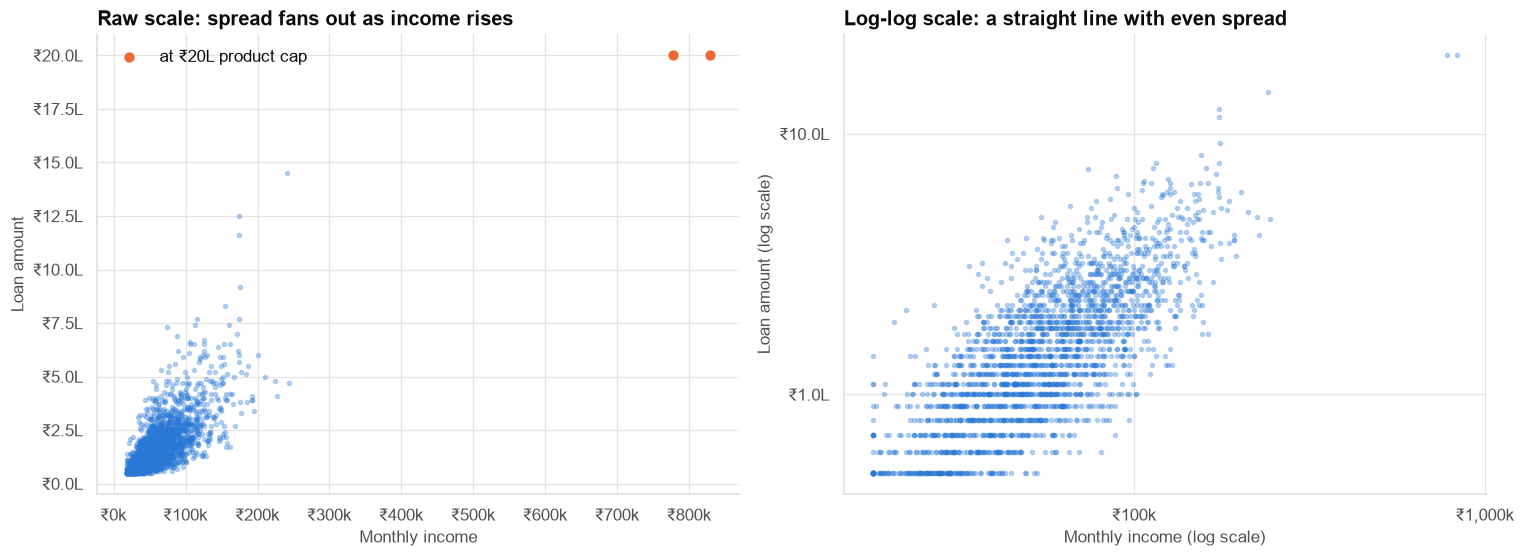

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
ax = axes[0]
ax.scatter(train["monthly_income"], train["loan_amount"], s=7, alpha=0.3, color=PRIMARY)
cap_rows = train["loan_amount"] == PRODUCT_CAP
ax.scatter(train.loc[cap_rows, "monthly_income"], train.loc[cap_rows, "loan_amount"], s=60, color=HIGHLIGHT, edgecolor="white",
           label="at ₹20L product cap", zorder=3)
ax.xaxis.set_major_formatter(kfmt); ax.yaxis.set_major_formatter(lfmt)
ax.set(title="Raw scale: spread fans out as income rises", xlabel="Monthly income", ylabel="Loan amount")
ax.legend(loc="upper left")
ax = axes[1]
ax.scatter(train["monthly_income"], train["loan_amount"], s=7, alpha=0.3, color=PRIMARY)
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(kfmt); ax.yaxis.set_major_formatter(lfmt)
ax.set(title="Log-log scale: a straight line with even spread", xlabel="Monthly income (log scale)", ylabel="Loan amount (log scale)")
fig.tight_layout()
save_fig(fig, "fig01_scatter_raw_vs_log", PATHS["figures"])
plt.show()

**Observation.** On the raw scale, loan amounts rise with income, but the vertical spread grows with income (a "fan").
The four capped customers sit far to the right. On log-log axes the cloud is a straight band of roughly constant
width.

**Interpretation.** Constant spread on a log scale means the noise is **multiplicative**: customers deviate from the
typical amount by similar **percentages** (±40%), not similar **rupee** amounts. A raw-scale regression assumes
the opposite (constant ± rupees), which matters for prediction ranges.

**Business implication.** A rule like "suggest X ± ₹1 lakh" would be too tight for high earners and too loose for low
earners. Ranges should be in percentage terms.

**Caveat.** The capped points are not evidence of what high earners *want* to borrow. They show what the product
*allows*.

## Section 8 — Method selection

```text
Outcome      : loan amount, continuous (₹), right-skewed, bounded by product limits
Predictor    : monthly income, continuous (₹), right-skewed
Goal         : (a) quantify ₹ per ₹ relationship (b) predict for a new customer with a range
Observations : 2,248 independent loans (different customers)
```

| Candidate | Verdict |
|---|---|
| Correlation | ❌ No units, no predictions: answers Q1 only |
| **Simple linear regression (OLS), raw scale** | ✅ Start here: directly answers "₹ per ₹10k". **Check its assumptions.** |
| **Log-log regression** | ✅ Expected to fit better given multiplicative noise. Gives an **elasticity** and percentage ranges |
| Multiple regression | Later (Case 07): other drivers exist, but the branch rule must use income only |
| Machine learning | ❌ One predictor, a clear shape: no need (Case 13's playbook) |

**The model.**  loan_amountᵢ = β₀ + β₁ · incomeᵢ + εᵢ

- **β₁ (slope):** the change in **average** loan amount for a ₹1 increase in income.
- **β₀ (intercept):** the average loan amount at income = 0, which is outside the data and has no meaning here
  (see 9.2).
- **εᵢ (error):** everything about customer *i*'s loan that income does not explain.

**Least squares** chooses β₀ and β₁ to minimise the sum of squared residuals Σ(yᵢ − ŷᵢ)². The solution is
β̂₁ = cov(x, y)/var(x) and β̂₀ = ȳ − β̂₁·x̄.

**Assumptions (LINE):** **L**inearity of the mean, **I**ndependence of errors, **N**ormality of errors (needed for
small-sample inference and for prediction intervals), **E**qual variance (homoscedasticity). Plus: no single point
dominates the fit.

## Section 9 — Fitting the raw-scale model

### 9.1 By hand, then with statsmodels

In [7]:
x, y = train["monthly_income"].to_numpy(), train["loan_amount"].to_numpy()
b1 = np.cov(x, y, ddof=1)[0, 1] / np.var(x, ddof=1)
b0 = y.mean() - b1 * x.mean()
print(f"By hand: slope β1 = cov(x,y)/var(x) = {b1:.4f};  intercept β0 = ȳ − β1·x̄ = {fmt_money(b0)}")

m_raw = smf.ols("loan_amount ~ monthly_income", data=train).fit()
print(m_raw.summary().tables[1])
print(f"\nR² = {m_raw.rsquared:.3f}   adjusted R² = {m_raw.rsquared_adj:.3f}   residual SE (RMSE) = {fmt_money(np.sqrt(m_raw.scale))}")
print(f"Check: correlation² = {np.corrcoef(x, y)[0, 1] ** 2:.3f} = R² (true for simple regression only)")

By hand: slope β1 = cov(x,y)/var(x) = 2.6378;  intercept β0 = ȳ − β1·x̄ = ₹10,890
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept       1.089e+04   3437.294      3.168      0.002    4149.562    1.76e+04
monthly_income     2.6378      0.046     56.866      0.000       2.547       2.729

R² = 0.590   adjusted R² = 0.590   residual SE (RMSE) = ₹85,897
Check: correlation² = 0.590 = R² (true for simple regression only)


### 9.2 Reading the output, line by line

| Output | Value (≈) | Meaning |
|---|---|---|
| **Slope (monthly_income)** | ≈ 2.6 | Each extra **₹1** of monthly income goes with about **₹2.6** more loan, **on average**. So each extra **₹10,000** of income goes with about **₹26,000** more borrowing. |
| **Std err of slope** | small | How much the slope would vary across samples |
| **t, P>\|t\|** | huge, < 0.001 | Tests H₀: β₁ = 0. With 2,000+ loans, any real relationship is "significant". Not informative by itself. |
| **[0.025, 0.975]** | narrow | 95% CI for the slope. The useful uncertainty statement. |
| **Intercept** | ≈ ₹10k | Predicted loan at income = 0. **Meaningless**: no customer earns ₹0, and nobody gets a ₹10k loan (the minimum is ₹50k). It just anchors the line. |
| **R²** | ≈ 0.6 | Income accounts for about 60% of the variation in loan amounts. **40% remains.** |
| **RMSE** | ≈ ₹86k | A typical prediction misses by this much. It is the same everywhere on the line, which, as we'll see, is wrong. |

**Making the intercept meaningful: centring.** If we regress on (income − ₹50,000), the intercept becomes the predicted
loan for a ₹50,000 earner, a number the business can use. The slope is unchanged.

In [8]:
m_centred = smf.ols("loan_amount ~ I(monthly_income - 50000)", data=train).fit()
print(f"Centred model: intercept = predicted loan at ₹50k income = {fmt_money(m_centred.params.iloc[0])}; "
      f"slope = {m_centred.params.iloc[1]:.4f} (unchanged)")

sst = ((y - y.mean()) ** 2).sum(); sse = (m_raw.resid ** 2).sum(); ssr = sst - sse
print(f"Variance decomposition: SST {sst:,.3e} = SSR {ssr:,.3e} (explained) + SSE {sse:,.3e} (unexplained);  R² = SSR/SST = {ssr / sst:.3f}")
slope_10k = m_raw.params["monthly_income"] * 10_000
ci_10k = m_raw.conf_int().loc["monthly_income"] * 10_000
print(f"Per ₹10,000 of income: +{fmt_money(slope_10k)} loan (95% CI {fmt_money(ci_10k[0])} – {fmt_money(ci_10k[1])})")

Centred model: intercept = predicted loan at ₹50k income = ₹142,779; slope = 2.6378 (unchanged)
Variance decomposition: SST 4.044e+13 = SSR 2.386e+13 (explained) + SSE 1.658e+13 (unexplained);  R² = SSR/SST = 0.590
Per ₹10,000 of income: +₹26,378 loan (95% CI ₹25,468 – ₹27,287)


## Section 10 — Confidence interval vs prediction interval

For a customer earning ₹60,000 a month, two different questions can be asked:

1. **"What is the *average* loan of customers earning ₹60k?"** → **confidence interval for the mean**. It reflects
   only uncertainty about where the line is, so it shrinks as n grows.
2. **"What will *this* ₹60k customer borrow?"** → **prediction interval**. It also includes the customer-to-customer
   scatter around the line (ε), so it never shrinks below ±2 RMSE, however much data you have.

In [9]:
grid = pd.DataFrame({"monthly_income": [30_000, 60_000, 100_000, 200_000]})
pr = m_raw.get_prediction(grid).summary_frame(alpha=0.05)
ci_pi = pd.DataFrame({"income": grid["monthly_income"].map(fmt_money), "predicted mean": pr["mean"].map(fmt_money),
                      "95% CI for the mean": [f"{fmt_money(a)} – {fmt_money(b)}" for a, b in zip(pr["mean_ci_lower"], pr["mean_ci_upper"])],
                      "95% PREDICTION interval": [f"{fmt_money(a)} – {fmt_money(b)}" for a, b in zip(pr["obs_ci_lower"], pr["obs_ci_upper"])]})
save_table(ci_pi, "ci_vs_pi_raw_model", PATHS["tables"], index=False)
ci_pi

,income,predicted mean,95% CI for the mean,95% PREDICTION interval
0,"₹30,000","₹90,024","₹85,374 – ₹94,673","₹-78,486 – ₹258,533"
1,"₹60,000","₹169,157","₹165,595 – ₹172,719","₹674 – ₹337,640"
2,"₹100,000","₹274,668","₹269,773 – ₹279,562","₹106,151 – ₹443,185"
3,"₹200,000","₹538,446","₹525,486 – ₹551,406","₹369,502 – ₹707,389"


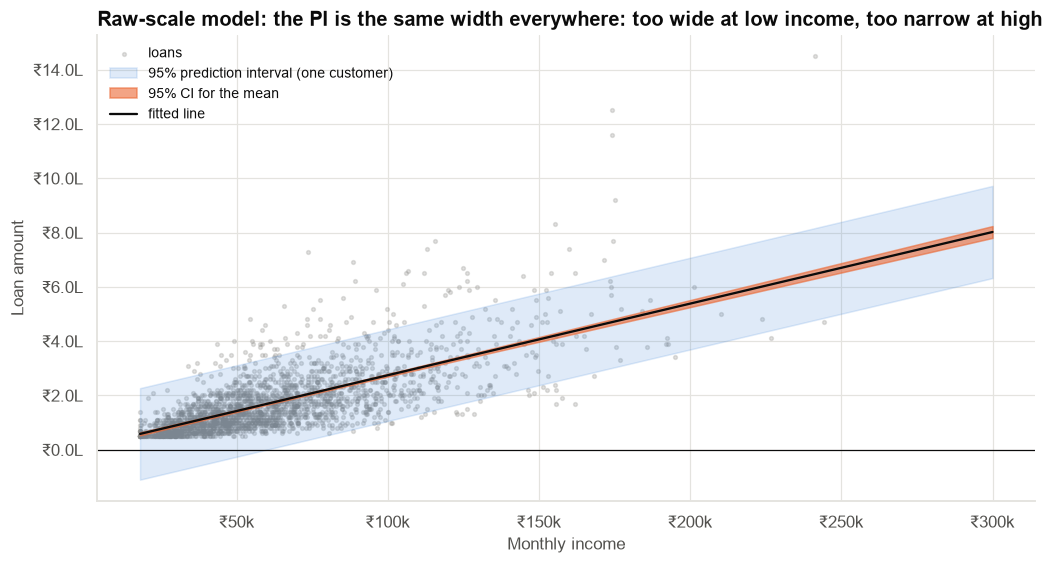

In [10]:
xs = pd.DataFrame({"monthly_income": np.linspace(18_000, 300_000, 200)})
band = m_raw.get_prediction(xs).summary_frame(alpha=0.05)
fig, ax = plt.subplots(figsize=(11, 5.5))
sub = train[train["monthly_income"] <= 300_000]
ax.scatter(sub["monthly_income"], sub["loan_amount"], s=6, alpha=0.25, color=INK_MUTED, label="loans")
ax.fill_between(xs["monthly_income"], band["obs_ci_lower"], band["obs_ci_upper"], color=PRIMARY, alpha=0.15, label="95% prediction interval (one customer)")
ax.fill_between(xs["monthly_income"], band["mean_ci_lower"], band["mean_ci_upper"], color=HIGHLIGHT, alpha=0.6, label="95% CI for the mean")
ax.plot(xs["monthly_income"], band["mean"], color=INK, lw=1.5, label="fitted line")
ax.axhline(0, color=INK, lw=0.8)
ax.xaxis.set_major_formatter(kfmt); ax.yaxis.set_major_formatter(lfmt)
ax.set(title="Raw-scale model: the PI is the same width everywhere: too wide at low income, too narrow at high",
       xlabel="Monthly income", ylabel="Loan amount")
ax.legend(loc="upper left", fontsize=9)
save_fig(fig, "fig02_ci_vs_pi_raw", PATHS["figures"])
plt.show()

**Observation.** The CI for the mean is a thin orange band hugging the line. The prediction interval is about ±₹1.7
lakh wide **at every income**. At ₹30k income its lower end is **below zero**, an impossible loan.

**Interpretation.** The CI is narrow because 2,000+ loans pin down the *average* very precisely. The PI is wide
because individual customers vary a lot. On the raw scale the model also assumes that variation is the same size for
everyone, which the scatter clearly contradicts.

**Business implication.** Showing branch staff the **CI** as "the range" would be a serious mistake. It would claim
precision we don't have for individual customers. The **PI** is the right range concept, but the raw-scale PI has the
wrong shape.

**Caveat.** Both intervals assume the model is right. The next section tests that.

## Section 11 — Assumption checks (diagnostics) for the raw-scale model

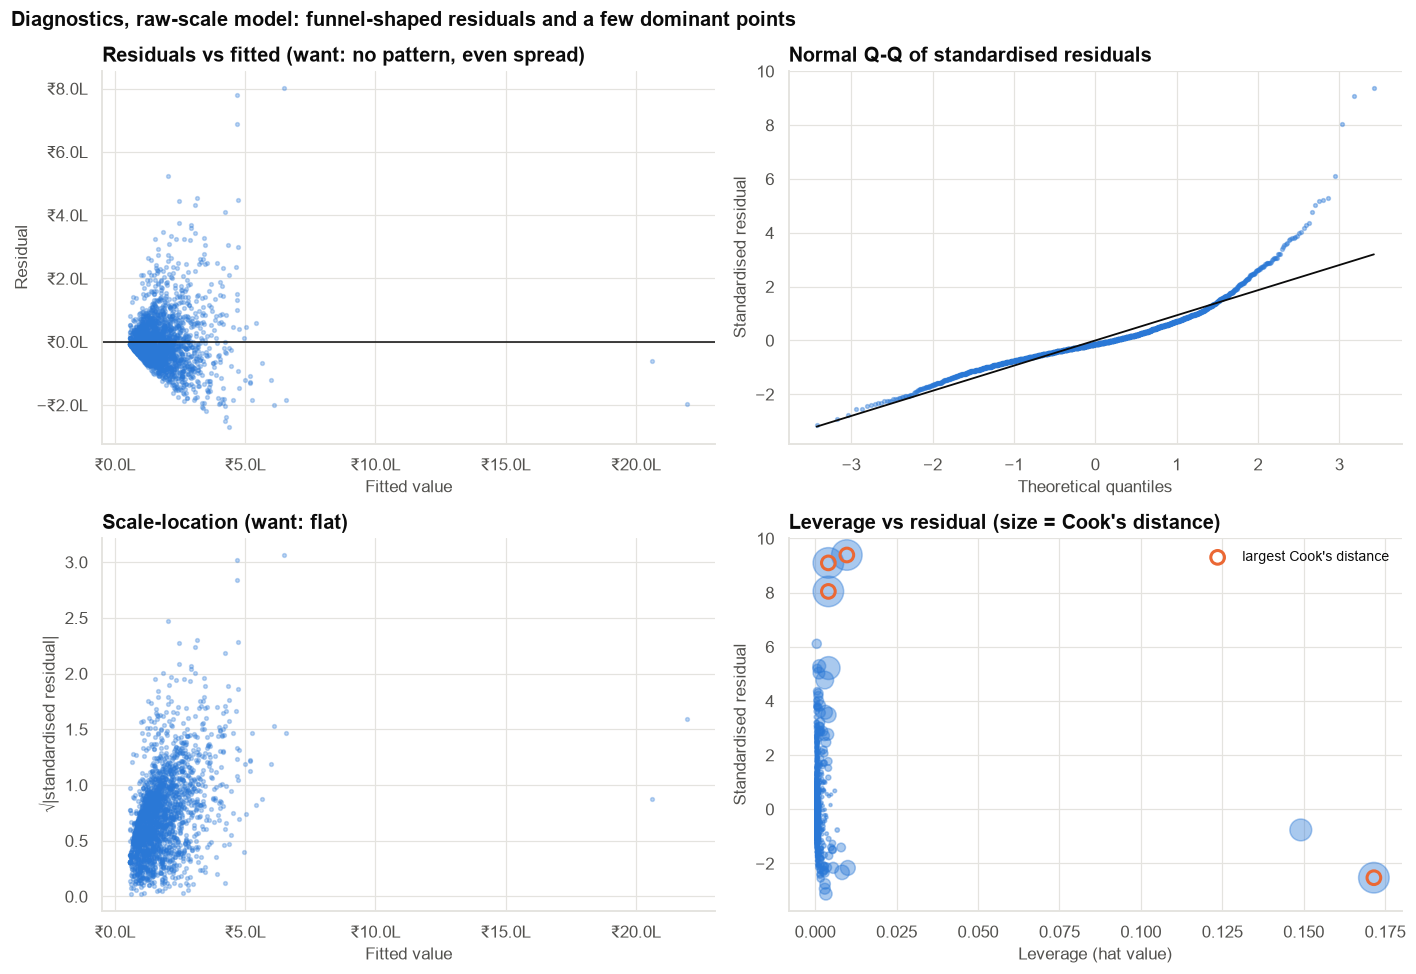

Breusch-Pagan test for constant variance: LM = 175, p = < 0.001


In [11]:
def diagnostic_panel(model, title, name, money=False):
    infl = OLSInfluence(model)
    fitted, resid = np.asarray(model.fittedvalues), np.asarray(model.resid)
    std_resid = np.asarray(infl.resid_studentized_internal)
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    ax = axes[0, 0]
    ax.scatter(fitted, resid, s=6, alpha=0.3, color=PRIMARY); ax.axhline(0, color=INK, lw=1)
    ax.set(title="Residuals vs fitted (want: no pattern, even spread)", xlabel="Fitted value", ylabel="Residual")
    if money:
        ax.xaxis.set_major_formatter(lfmt); ax.yaxis.set_major_formatter(lfmt)
    ax = axes[0, 1]
    (osm, osr), (sl, ic, _) = stats.probplot(std_resid, dist="norm")
    ax.scatter(osm, osr, s=6, alpha=0.4, color=PRIMARY); ax.plot(osm, sl * osm + ic, color=INK, lw=1.2)
    ax.set(title="Normal Q-Q of standardised residuals", xlabel="Theoretical quantiles", ylabel="Standardised residual")
    ax = axes[1, 0]
    ax.scatter(fitted, np.sqrt(np.abs(std_resid)), s=6, alpha=0.3, color=PRIMARY)
    ax.set(title="Scale-location (want: flat)", xlabel="Fitted value", ylabel="√|standardised residual|")
    if money:
        ax.xaxis.set_major_formatter(lfmt)
    ax = axes[1, 1]
    lev, cooks = np.asarray(infl.hat_matrix_diag), np.asarray(infl.cooks_distance[0])
    ax.scatter(lev, std_resid, s=np.clip(cooks * 4000, 4, 400), alpha=0.4, color=PRIMARY)
    top = np.argsort(cooks)[-4:]
    ax.scatter(lev[top], std_resid[top], s=80, facecolor="none", edgecolor=HIGHLIGHT, lw=2, label="largest Cook's distance")
    ax.set(title="Leverage vs residual (size = Cook's distance)", xlabel="Leverage (hat value)", ylabel="Standardised residual")
    ax.legend(loc="upper right", fontsize=9)
    fig.suptitle(title, x=0.01, ha="left", fontsize=13, fontweight="bold")
    fig.tight_layout()
    save_fig(fig, name, PATHS["figures"])
    plt.show()
    return infl

infl_raw = diagnostic_panel(m_raw, "Diagnostics, raw-scale model: funnel-shaped residuals and a few dominant points", "fig03_diagnostics_raw", money=True)
bp = sms.het_breuschpagan(m_raw.resid, m_raw.model.exog)
print(f"Breusch-Pagan test for constant variance: LM = {bp[0]:.0f}, p = {fmt_p(bp[1])}")

**Reading the four diagnostic plots**

| Plot | What we see | Assumption | Verdict |
|---|---|---|---|
| Residuals vs fitted | A funnel: residuals spread out as fitted values grow | Equal variance | ❌ **Heteroscedasticity** (Breusch-Pagan p ≈ 0) |
| Normal Q-Q | Points curve away in both tails: heavier tails, right skew | Normal errors | ❌ (matters for PIs) |
| Scale-location | Rising trend | Equal variance | ❌ Confirms the funnel |
| Leverage vs residual | A few points with very high leverage (the ₹6–9 lakh earners) dominate | No dominant points | ⚠️ Investigate |

**What these violations do**

- **The slope estimate is still unbiased** (OLS needs linearity and exogeneity for that, not constant variance).
- **Its standard error is wrong.** The usual formula assumes equal variance. **Robust (HC3) standard errors** fix
  inference about the slope without changing it. Here the robust SE is about **twice** the classical one, so the
  classical CI was overconfident.
- **Prediction intervals are wrong** in shape, and no SE correction fixes that. The model of the spread itself must
  change. → **log-log model**.

In [12]:
m_raw_hc3 = smf.ols("loan_amount ~ monthly_income", data=train).fit(cov_type="HC3")
print(f"Slope SE: classical {m_raw.bse['monthly_income']:.4f}   robust HC3 {m_raw_hc3.bse['monthly_income']:.4f}  "
      f"(ratio {m_raw_hc3.bse['monthly_income'] / m_raw.bse['monthly_income']:.1f}×)")

Slope SE: classical 0.0464   robust HC3 0.0936  (ratio 2.0×)


## Section 12 — Influential points: the four capped high earners

In [13]:
hi_lev = train["monthly_income"] > 500_000
m_wo = smf.ols("loan_amount ~ monthly_income", data=train[~hi_lev]).fit()
cook = pd.Series(infl_raw.cooks_distance[0], index=train.index)
print(f"Cook's distance of the 4 capped high earners: {cook[hi_lev].round(2).tolist()}  (rule of thumb: > 4/n = {4 / len(train):.4f} is notable)")
infl_tbl = pd.DataFrame({"with the 4 capped earners": [m_raw.params["monthly_income"] * 1e4, m_raw.rsquared],
                         "without them": [m_wo.params["monthly_income"] * 1e4, m_wo.rsquared]},
                        index=["₹ loan per ₹10k income", "R²"])
save_table(infl_tbl, "influence_capped_earners", PATHS["tables"])
infl_tbl

Cook's distance of the 4 capped high earners: [0.05, 0.66]  (rule of thumb: > 4/n = 0.0018 is notable)


,with the 4 capped earners,without them
₹ loan per ₹10k income,"26,377.7783","27,212.8345"
R²,0.5900,0.5110


Only **two** of the four capped earners fell into the training data, yet those two loans out of 2,249 **raise R² from
about 0.51 to 0.59**. One of them has a Cook's distance of about 0.7, hundreds of times the usual 4/n warning level.
They sit so far to the right that they act as a lever. Because their loans are **capped** at ₹20 lakh, they also pull
the slope *down* slightly (₹27.2k → ₹26.4k per ₹10k).

> **High leverage + extreme position = influence.** A point far from the others in X can dominate a regression even
> when its Y looks unremarkable. Always check Cook's distance (Case 10 goes deeper). Here the right decision is not to
> delete them silently: (1) the branch rule is for customers up to about ₹3–4 lakh income, so we **restrict the
> model's domain**; (2) we report that above the cap, the product limit, not income, determines the amount.

**R² went *up* when we added odd points.** A higher R² is not a sign of a better model. Here it comes from 4 lever
points that happen to line up.

## Section 13 — The log-log model

  log(loan_amount) = β₀ + β₁ · log(income) + ε

On log scales, a straight line means amount ∝ income^β₁. The slope **β₁ is an elasticity**: a **1% increase in income
goes with a β₁% increase in loan amount**. Multiplicative noise becomes additive and constant, which fixes the
funnel.

In [14]:
dom = train[train["monthly_income"] <= 400_000].copy()        # the rule's intended domain
m_log = smf.ols("np.log(loan_amount) ~ np.log(monthly_income)", data=dom).fit()
print(m_log.summary().tables[1])
el, el_ci = m_log.params.iloc[1], m_log.conf_int().iloc[1]
s_log = np.sqrt(m_log.scale)
print(f"\nElasticity = {el:.3f} (95% CI {el_ci[0]:.3f} – {el_ci[1]:.3f}): +10% income -> +{(1.1 ** el - 1):.1%} loan amount")
print(f"Residual SD on log scale = {s_log:.3f}  ->  a typical customer is within ×/÷ {np.exp(s_log):.2f} of the typical amount")
print(f"R² (log scale) = {m_log.rsquared:.3f}")
bp_log = sms.het_breuschpagan(m_log.resid, m_log.model.exog)
print(f"Breusch-Pagan on log model: LM = {bp_log[0]:.1f}, p = {fmt_p(bp_log[1])}")

                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  1.8450      0.190      9.709      0.000       1.472       2.218
np.log(monthly_income)     0.9194      0.017     52.881      0.000       0.885       0.953



Elasticity = 0.919 (95% CI 0.885 – 0.953): +10% income -> +9.2% loan amount
Residual SD on log scale = 0.406  ->  a typical customer is within ×/÷ 1.50 of the typical amount
R² (log scale) = 0.555
Breusch-Pagan on log model: LM = 13.1, p = < 0.001


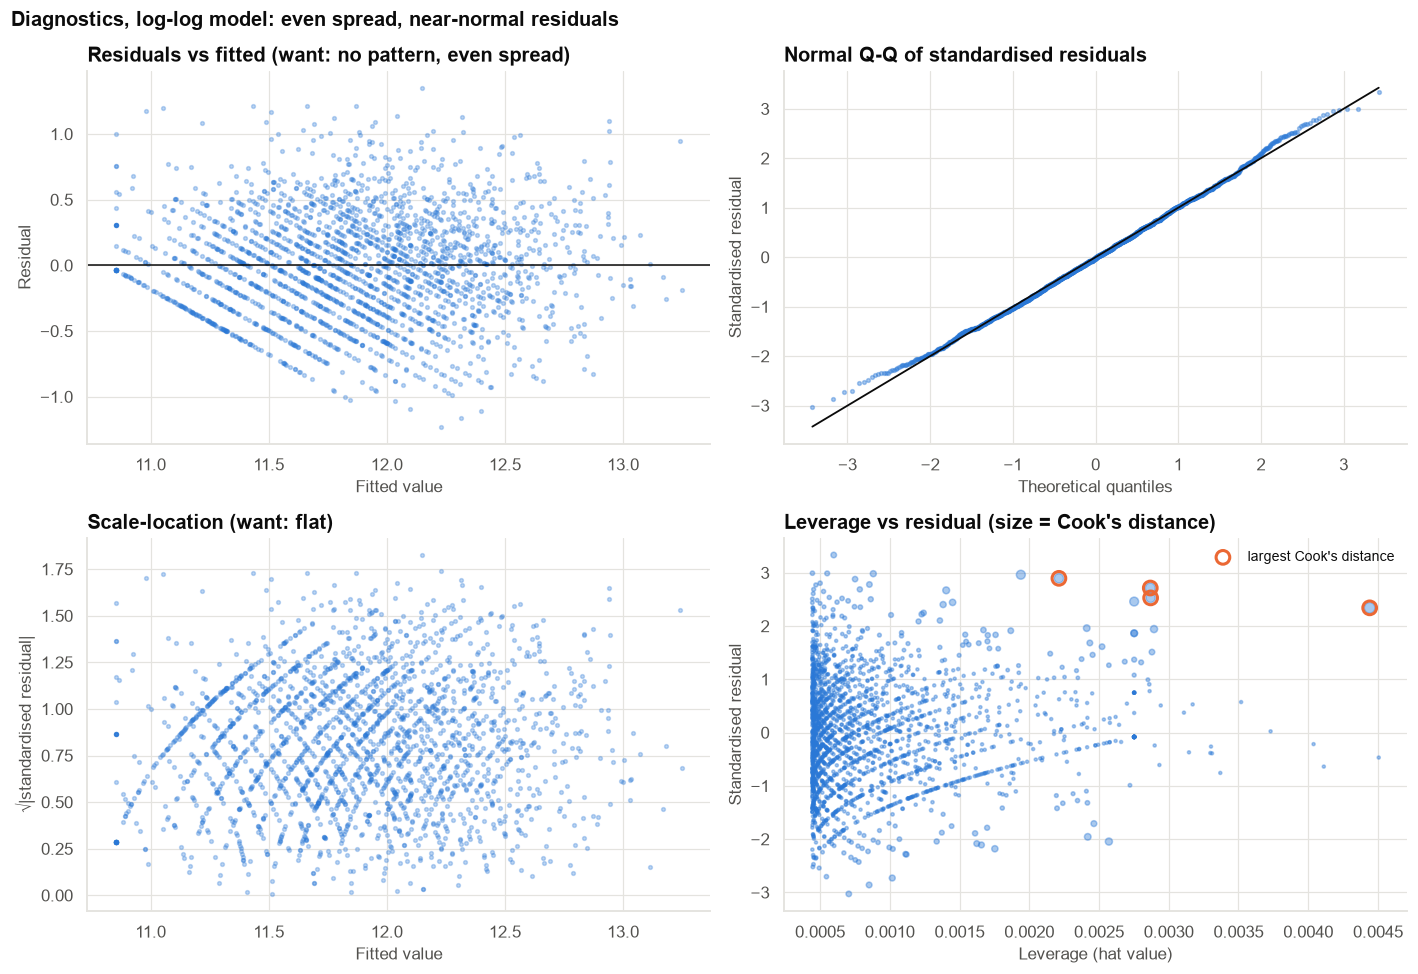

In [15]:
infl_log = diagnostic_panel(m_log, "Diagnostics, log-log model: even spread, near-normal residuals", "fig04_diagnostics_log")

**The log-log model's residuals look far healthier.** The funnel is gone, the Q-Q plot is close to straight, and no
point dominates. Breusch-Pagan still flags some remaining unevenness: with 2,000+ loans it detects even mild
departures. The visible causes are the ₹50k floor and the round-number amounts. This is a case where the test is
statistically significant but practically minor (look at the plot, not just the p-value).

**Interpreting the elasticity.** An elasticity just below 1 means loan amounts rise **almost proportionally** with
income: a customer earning 10% more borrows about 9% more. In rupees, the effect per ₹10k is **larger for higher
earners**, because 10k is a smaller *percentage* of a big income but applies to a bigger base. So "₹26k per ₹10k"
from the raw model is an average that is wrong for most customers.

### 13.1 Predictions and ranges from the log-log model

In [16]:
def log_model_predict(model, incomes, level=0.80):
    g = pd.DataFrame({"monthly_income": incomes})
    fr = model.get_prediction(g).summary_frame(alpha=1 - level)
    return pd.DataFrame({"income": incomes, "typical (median) amount": np.exp(fr["mean"]),
                         "low": np.exp(fr["obs_ci_lower"]), "high": np.exp(fr["obs_ci_upper"])})

offer = log_model_predict(m_log, [25_000, 40_000, 60_000, 100_000, 150_000, 250_000])
offer_fmt = offer.assign(**{c: offer[c].map(fmt_money) for c in offer.columns})
save_table(offer, "pre_offer_table_log_model", PATHS["tables"], index=False)
offer_fmt.rename(columns={"low": "80% range: low", "high": "80% range: high"})

,income,typical (median) amount,80% range: low,80% range: high
0,"₹25,000","₹69,913","₹41,546","₹117,649"
1,"₹40,000","₹107,701","₹64,017","₹181,193"
2,"₹60,000","₹156,354","₹92,941","₹263,035"
3,"₹100,000","₹250,075","₹148,626","₹420,769"
4,"₹150,000","₹363,046","₹215,702","₹611,040"
5,"₹250,000","₹580,659","₹344,784","₹977,901"


**Back-transforming from logs.** exp(predicted log amount) is the predicted **median** loan for that income (half of
customers borrow more, half less). That is exactly what a "suggested offer" should be. The **mean** would be higher by
a factor of about exp(σ²/2) ≈ 1.08 ("smearing"); use it when you need *totals*, e.g. forecasting disbursements.
Prediction intervals transform directly: exp(lower), exp(upper). They are **asymmetric in rupees** and never
negative.

For branch use we show an **80%** range ("most customers like this borrow between…"). A 95% range would be too wide
to be useful for a conversation, and 80% is honest about what we know.

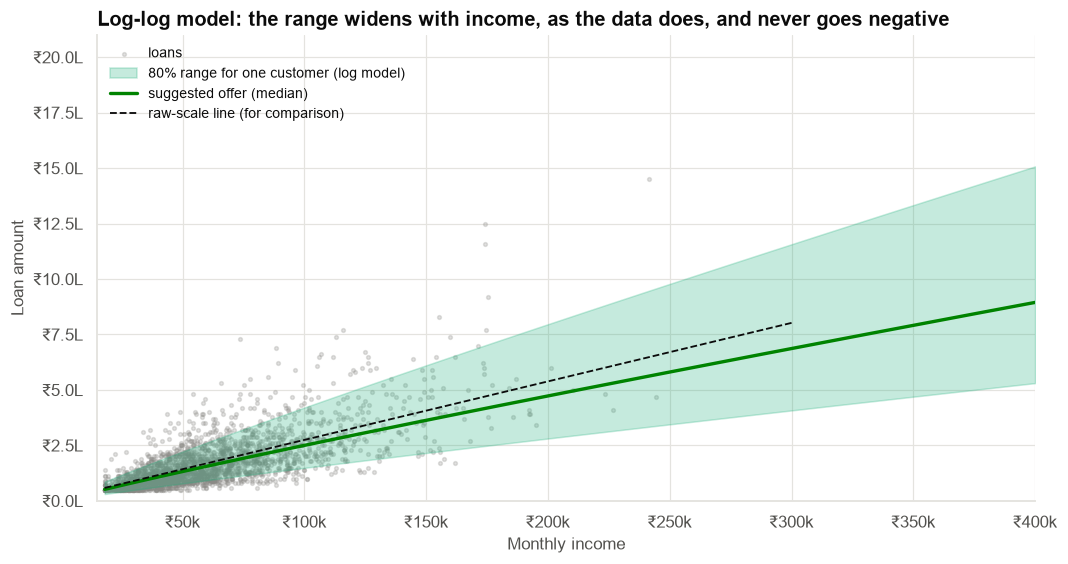

In [17]:
xs2 = np.linspace(18_000, 400_000, 200)
pl = log_model_predict(m_log, xs2, level=0.80)
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.scatter(dom["monthly_income"], dom["loan_amount"], s=6, alpha=0.25, color=INK_MUTED, label="loans")
ax.fill_between(xs2, pl["low"], pl["high"], color=COLORS["aqua"], alpha=0.25, label="80% range for one customer (log model)")
ax.plot(xs2, pl["typical (median) amount"], color=COLORS["green"], lw=2.2, label="suggested offer (median)")
ax.plot(xs["monthly_income"], band["mean"], color=INK, lw=1.2, ls="--", label="raw-scale line (for comparison)")
ax.xaxis.set_major_formatter(kfmt); ax.yaxis.set_major_formatter(lfmt)
ax.set_xlim(15_000, 400_000); ax.set_ylim(0, 2_100_000)
ax.set(title="Log-log model: the range widens with income, as the data does, and never goes negative",
       xlabel="Monthly income", ylabel="Loan amount")
ax.legend(loc="upper left", fontsize=9)
save_fig(fig, "fig05_log_model_ranges", PATHS["figures"])
plt.show()

## Section 14 — Validation on the holdout loans

The real test of a prediction rule: on loans **not used to fit it**, does the stated range contain the actual amount as
often as it claims (80%), **for low and high earners alike**?

In [18]:
tst = test[test["monthly_income"] <= 400_000].copy()
# Raw-scale model 80% PI
raw_pi = m_raw.get_prediction(tst[["monthly_income"]]).summary_frame(alpha=0.20)
tst["raw_in"] = (tst["loan_amount"] >= raw_pi["obs_ci_lower"].values) & (tst["loan_amount"] <= raw_pi["obs_ci_upper"].values)
lp = log_model_predict(m_log, tst["monthly_income"].to_numpy(), level=0.80)
tst["log_in"] = (tst["loan_amount"].values >= lp["low"].values) & (tst["loan_amount"].values <= lp["high"].values)
tst["raw_pred"] = raw_pi["mean"].values
tst["log_pred"] = lp["typical (median) amount"].values
tst["income_band"] = pd.qcut(tst["monthly_income"], 5, labels=["lowest 20%", "20–40%", "40–60%", "60–80%", "top 20%"])
cov = tst.groupby("income_band", observed=True).agg(loans=("loan_id", "size"), raw_model_coverage=("raw_in", "mean"),
                                                     log_model_coverage=("log_in", "mean"))
cov.loc["ALL"] = [len(tst), tst["raw_in"].mean(), tst["log_in"].mean()]
save_table(cov, "holdout_pi_coverage", PATHS["tables"])
mae = pd.Series({"raw model MAE": (tst["loan_amount"] - tst["raw_pred"]).abs().mean(),
                 "log model MAE": (tst["loan_amount"] - tst["log_pred"]).abs().mean(),
                 "raw model median abs % error": ((tst["loan_amount"] - tst["raw_pred"]).abs() / tst["loan_amount"]).median(),
                 "log model median abs % error": ((tst["loan_amount"] - tst["log_pred"]).abs() / tst["loan_amount"]).median()})
save_table(mae.to_frame("value"), "holdout_errors", PATHS["tables"])
display(mae.to_frame("value"))
cov.style.format({"loans": "{:,.0f}", "raw_model_coverage": "{:.0%}", "log_model_coverage": "{:.0%}"})

,value
raw model MAE,"55,084.6332"
log model MAE,"52,394.3662"
raw model median abs % error,0.2814
log model median abs % error,0.2584


,loans,raw_model_coverage,log_model_coverage
income_band,,,
lowest 20%,150,99%,86%
20–40%,151,95%,73%
40–60%,148,93%,78%
60–80%,148,91%,86%
top 20%,150,71%,82%
ALL,747,90%,81%


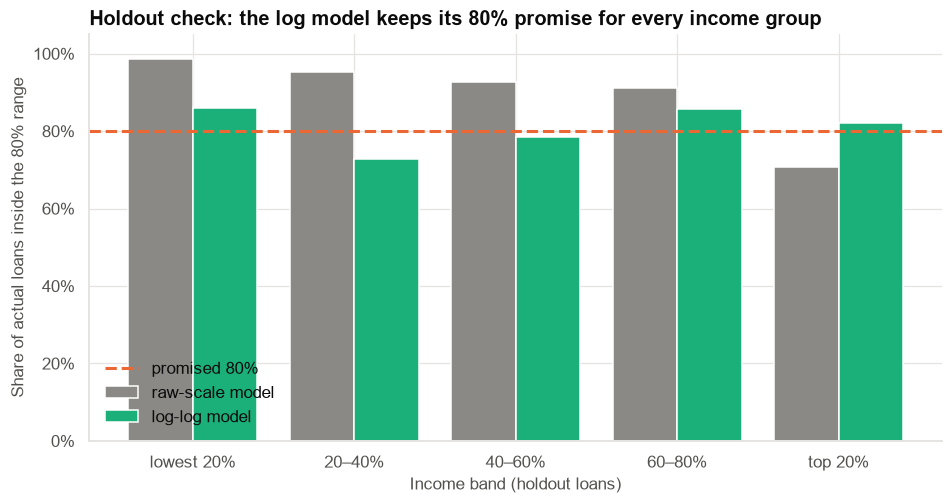

In [19]:
fig, ax = plt.subplots(figsize=(10, 4.8))
c = cov.drop(index="ALL")
xpos = np.arange(len(c))
ax.bar(xpos - 0.2, c["raw_model_coverage"], width=0.4, color=INK_MUTED, label="raw-scale model")
ax.bar(xpos + 0.2, c["log_model_coverage"], width=0.4, color=COLORS["aqua"], label="log-log model")
ax.axhline(0.80, color=HIGHLIGHT, ls="--", lw=2, label="promised 80%")
ax.set_xticks(xpos, c.index)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylim(0, 1.05)
ax.set(title="Holdout check: the log model keeps its 80% promise for every income group",
       xlabel="Income band (holdout loans)", ylabel="Share of actual loans inside the 80% range")
ax.legend(loc="lower left")
save_fig(fig, "fig06_holdout_coverage", PATHS["figures"])
plt.show()

**Observation.** The raw-scale model's 80% range covers 99% of low earners (far too wide) but only about 71% of the top
income band (too narrow); overall it covers 90%, because its ranges are mostly too wide. The log model covers 73–86%
in each band. With about 150 holdout loans per band, coverage estimates carry roughly ±6 points of sampling noise, so
these are all consistent with the promised 80%.

**Interpretation.** A range that is "right on average" can be wrong for every group. **Calibration within groups** is
what separates a usable rule from a misleading one. This is why we check diagnostics and group-level performance, not
only overall metrics.

**Business implication.** With the raw model, branch staff would routinely offer ranges that are unrealistic for
high-income customers, exactly the most valuable segment.

## Section 15 — Extrapolation

In [20]:
for inc in [400_000, 800_000, 2_000_000]:
    p_ = log_model_predict(m_log, [inc]).iloc[0]
    print(f"Income {fmt_money(inc):>12}: log model suggests {fmt_money(p_['typical (median) amount'])}  "
          f"(product cap {fmt_money(PRODUCT_CAP)}; training data max ≈ {fmt_money(dom['monthly_income'].max())})")

Income     ₹400,000: log model suggests ₹894,502  (product cap ₹2,000,000; training data max ≈ ₹244,200)
Income     ₹800,000: log model suggests ₹1,691,754  (product cap ₹2,000,000; training data max ≈ ₹244,200)
Income   ₹2,000,000: log model suggests ₹3,928,153  (product cap ₹2,000,000; training data max ≈ ₹244,200)


Regression describes the relationship **within the range of the data**. Beyond it (incomes above ~₹4 lakh) we have
almost no evidence, and the product cap changes the rules entirely. The rule must state its **domain**: for incomes
above ₹4 lakh/month, offer the cap and refer to a relationship manager.

## Section 16 — Results

In [21]:
results = pd.DataFrame([
    ["Raw model: ₹ loan per ₹10k income", m_raw.params["monthly_income"] * 1e4, *(m_raw_hc3.conf_int().loc["monthly_income"] * 1e4).tolist()],
    ["Raw model: R²", m_raw.rsquared, np.nan, np.nan],
    ["Raw model: RMSE (₹)", np.sqrt(m_raw.scale), np.nan, np.nan],
    ["Raw model: slope per ₹10k without 4 capped earners", m_wo.params["monthly_income"] * 1e4, *(m_wo.conf_int().loc["monthly_income"] * 1e4).tolist()],
    ["Log model: elasticity", el, el_ci[0], el_ci[1]],
    ["Log model: R² (log scale)", m_log.rsquared, np.nan, np.nan],
    ["Log model: residual SD (log)", s_log, np.nan, np.nan],
    ["Holdout 80% PI coverage, raw model (lowest / top band)", cov.iloc[0]["raw_model_coverage"], cov.iloc[4]["raw_model_coverage"], np.nan],
    ["Holdout 80% PI coverage, log model (lowest / top band)", cov.iloc[0]["log_model_coverage"], cov.iloc[4]["log_model_coverage"], np.nan],
], columns=["quantity", "estimate", "ci_low / value 2", "ci_high"]).set_index("quantity")
save_table(results, "key_results", PATHS["tables"])
results

,estimate,ci_low / value 2,ci_high
quantity,,,
Raw model: ₹ loan per ₹10k income,"26,377.7783","24,544.0147","28,211.5419"
Raw model: R²,0.5900,NaN,NaN
Raw model: RMSE (₹),"85,896.9490",NaN,NaN
Raw model: slope per ₹10k without 4 capped earners,"27,212.8345","26,111.1565","28,314.5124"
Log model: elasticity,0.9194,0.8853,0.9535
Log model: R² (log scale),0.5547,NaN,NaN
Log model: residual SD (log),0.4057,NaN,NaN
"Holdout 80% PI coverage, raw model (lowest / top band)",0.9867,0.7067,NaN
"Holdout 80% PI coverage, log model (lowest / top band)",0.8600,0.8200,NaN


## Section 17 — Interpretation

**Strength.** Income explains roughly 60% of the variation in loan amounts on the raw scale (R² ≈ 0.59, partly inflated by
two capped high earners) and about the same share on the log scale. Income is the dominant driver, but **40% of the
variation is due to other things** (existing debts, purpose, employment type and so on: Case 07).

**₹ per ₹10k (raw model).** On average, each extra ₹10,000 of monthly income goes with about **₹26,000** more borrowing
(95% robust CI shown above). This is a valid **average** summary, but it is not the same for everyone: the data say the
relationship is **proportional**, not additive.

**Elasticity (log model).** A 10% higher income goes with about **9% higher** loan amount (elasticity ≈ 0.92, 95% CI
≈ 0.89–0.95). A typical customer borrows within about **×/÷ 1.5** of the amount predicted from their income.

**Model choice.** The raw-scale model violates the equal-variance and normality assumptions. Its slope is fine on
average, but its prediction ranges are wrong in a systematic way: too wide for low earners, too narrow for high earners.
The log-log model fixes this: on holdout loans its 80% ranges contain the actual amount 73–86% of the time across
income bands, within sampling noise of 80%.

**Language.** This is a **predictive association**. It describes how much customers *with* higher incomes borrow. It
does not say that raising someone's income would make them borrow more, and it reflects current approval policy (we
only see approved loans).

## Section 18 — What can we say?

### ✅ We can confidently say
- Loan amount rises almost proportionally with income (elasticity ≈ 0.92).
- Income alone explains a large share, but far from all, of the variation in loan amounts.
- A log-log rule gives honest 80% ranges for customers with incomes up to ≈ ₹4 lakh/month.

### 📊 We have evidence that
- Ranges built from the raw-scale model would mislead branch staff for high-income customers.
- The capped high earners distort raw-scale results (R², leverage).

### ❌ We cannot conclude
- What customers above ≈ ₹4 lakh/month would borrow without the cap.
- That income *causes* the loan size (approval policy shapes amounts too).
- What drives the remaining ≈ 40% of variation (not in this model).

### 🔍 We would need additional analysis or data to conclude
- **Multiple regression** with employment type, existing obligations and loan purpose (Case 07).
- Applications data (including declined and reduced offers) to separate customer demand from policy limits.

## Section 19 — Business interpretation

| Statistical finding | Data scientist interpretation | Business interpretation | Business action |
|---|---|---|---|
| Elasticity ≈ 0.92 | Proportional relationship | Customers borrow roughly a fixed number of months of income | Express offers as "≈ 2.5–3 months of income" |
| Raw slope ≈ ₹26k per ₹10k (average) | Additive summary of a proportional pattern | Fine for the planning deck as an average, not for individual offers | Use in the deck with a footnote |
| PI vs CI | CI = average customer; PI = one customer | The realistic range for a customer is wide (×/÷ 1.5) | Show staff the 80% PI, never the CI |
| Holdout coverage 73–86% across bands (log model) vs 71–99% (raw) | Well-calibrated ranges | The rule is trustworthy across income levels | Deploy the log-log rule for incomes ≤ ₹4 lakh |
| Influence of capped earners; extrapolation | Outside the model's domain | The cap, not income, drives very large loans | Above ₹4 lakh/month: offer cap, refer to RM |

## Section 20 — Limitations

- **Income is the only predictor:** ranges are wide because other drivers are ignored.
- **Approved, disbursed loans only:** amounts reflect both customer demand and approval policy.
- **Censoring at the cap and floor** affects both tails.
- **Six months of data**: offers may shift with interest rates and seasons.
- **Synthetic data.**

## Section 21 — Final recommendation

1. **Adopt the log-log rule** for branch pre-offers: suggested amount = typical (median) amount for the income, with an
   **80% range**, for incomes up to ₹4 lakh/month (table in Section 13.1).
2. **Above ₹4 lakh/month:** offer the product cap and refer to a relationship manager.
3. In the planning deck, quote **"≈ ₹26,000 more borrowing per extra ₹10,000 of monthly income, on average"** and
   the elasticity (**+10% income → ≈ +9% loan**), with ranges.
4. **Next:** add employment type and existing obligations to narrow the ranges (Case 07).

## Section 22 — What would I do next?

- Multiple regression with additional drivers (Case 07); compare holdout coverage and range widths.
- Monitor the rule monthly: holdout coverage by income band.
- Collect requested (not just approved) amounts to model demand separately from policy.

---

### Concepts covered
Y = β₀ + β₁X + ε · least squares · slope and intercept interpretation · centring · SST/SSR/SSE and R² · R² = r² in simple
regression · RMSE · SE, t-test and CI for the slope · CI for the mean vs prediction interval · LINE assumptions ·
residual, Q-Q, scale-location and leverage plots · Breusch-Pagan test · heteroscedasticity-robust (HC3) SEs ·
leverage and Cook's distance · log-log model and elasticity · back-transformation (median vs mean, smearing) ·
holdout validation and calibration of intervals · extrapolation and model domain.

### Exercises
1. Fit a **log-linear** model (log amount on raw income). How does its interpretation differ from log-log?
2. Compute the raw model's 80% PI coverage after **removing** the four capped earners. Does it fix the high-income
   problem? Why not?
3. What sample size would halve the CI for the elasticity? Would it narrow the prediction interval? Why not?
4. Write the branch-staff instruction for a ₹75,000 earner in one sentence.